In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Load the dataset
url = "https://raw.githubusercontent.com/jakevdp/data-CDCbirths/master/births.csv"
births = pd.read_csv(url)

# Display the first five rows
print("--- First 5 Rows ---")
print(births.head())

# Print shape and column data types
print("\n--- Shape of DataFrame ---")
print(births.shape)

print("\n--- Column Data Types ---")
print(births.dtypes)

--- First 5 Rows ---
   year  month  day gender  births
0  1969      1  1.0      F    4046
1  1969      1  1.0      M    4440
2  1969      1  2.0      F    4454
3  1969      1  2.0      M    4548
4  1969      1  3.0      F    4548

--- Shape of DataFrame ---
(15547, 5)

--- Column Data Types ---
year        int64
month       int64
day       float64
gender     object
births      int64
dtype: object


--- Total Births by Decade and Gender ---
gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428

--- (a) Are Male Births Greater in Every Decade? ---
decade
1960    True
1970    True
1980    True
1990    True
2000    True
Name: male_greater, dtype: bool

--- (b) Male-to-Female Ratio and Percentage Excess ---
gender     ratio  pct_excess
decade                      
1960    1.052997    5.299738
1970    1.052787    5.278676
1980    1.050960    5.096030
1990    1.048312    4.831239
2000    1.048116    4.811587


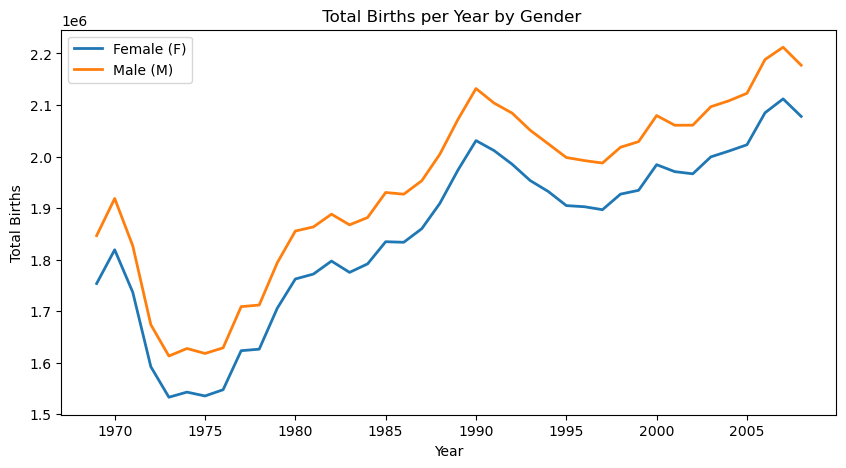

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Add a decade column using integer division
births['decade'] = 10 * (births['year'] // 10)

# 2. Build a pivot table of total births with decade as index and gender as columns
pivot_decade = births.pivot_table(index='decade', columns='gender', values='births', aggfunc='sum')
print("--- Total Births by Decade and Gender ---")
print(pivot_decade)

# (a) Verify that male births outnumber female births in every decade
pivot_decade['male_greater'] = pivot_decade['M'] > pivot_decade['F']
print("\n--- (a) Are Male Births Greater in Every Decade? ---")
print(pivot_decade['male_greater'])

# (b) Compute the male-to-female ratio and percentage excess
pivot_decade['ratio'] = pivot_decade['M'] / pivot_decade['F']
pivot_decade['pct_excess'] = ((pivot_decade['M'] - pivot_decade['F']) / pivot_decade['F']) * 100
print("\n--- (b) Male-to-Female Ratio and Percentage Excess ---")
print(pivot_decade[['ratio', 'pct_excess']])

# (c) Plot total births per year by gender
pivot_year = births.pivot_table(index='year', columns='gender', values='births', aggfunc='sum')
pivot_year.plot(figsize=(10, 5), linewidth=2)
plt.title(" Total Births per Year by Gender")
plt.xlabel("Year")
plt.ylabel("Total Births")
plt.legend(["Female (F)", "Male (M)"])
plt.show()

In [5]:
import numpy as np
import pandas as pd

# (a) Compute robust mean (mu) and robust standard deviation (sig) using quartiles
quartiles = np.percentile(births['births'], [25, 50, 75])
mu = quartiles[1]  # Median as robust mean
sig = 0.74 * (quartiles[2] - quartiles[0])  # Robust standard deviation

print(f"Robust Mean (mu): {mu}")
print(f"Robust Std Dev (sig): {sig}")

# (b) Use the query() method to keep only rows within 5 sigma of mu
initial_count = len(births)
births_cleaned = births.query('(births > @mu - 5 * @sig) & (births < @mu + 5 * @sig)')
removed_count = initial_count - len(births_cleaned)
print(f"Total rows removed: {removed_count}")

# (c) Convert the day column to integers with astype(int)
births_cleaned['day'] = births_cleaned['day'].astype(int)
print("\nDay column successfully converted to integer. Sample dtypes:")
print(births_cleaned.dtypes)

Robust Mean (mu): 4814.0
Robust Std Dev (sig): 689.31
Total rows removed: 937

Day column successfully converted to integer. Sample dtypes:
year       int64
month      int64
day        int64
gender    object
births     int64
decade     int64
dtype: object


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_13036\2981321435.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  births_cleaned['day'] = births_cleaned['day'].astype(int)


--- Mean Births by Day of Week and Decade ---
decade            1960         1970         1980
dayofweek                                       
Monday     5063.826923  4689.097701  5276.907249
Tuesday    5286.096154  4885.252399  5503.842553
Wednesday  5074.622642  4750.376200  5367.642553
Thursday   4978.288462  4696.923372  5333.485106
Friday     5107.884615  4782.095785  5393.087234
Saturday   4651.057692  4207.784483  4483.901064
Sunday     4342.346154  3979.278736  4308.120469


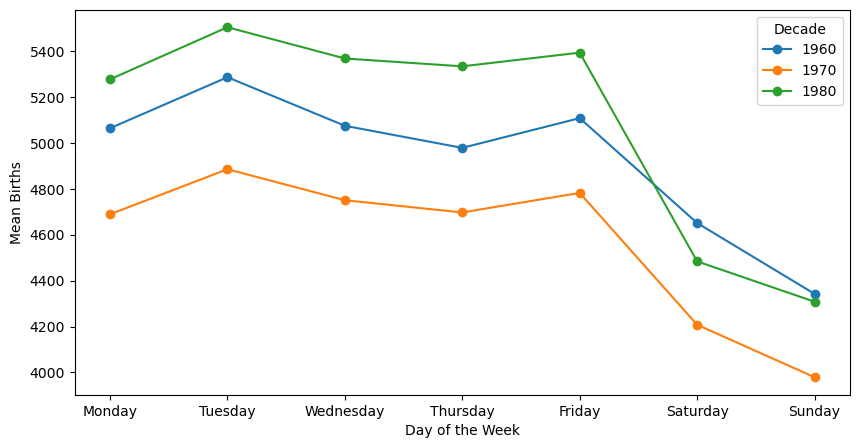

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

# Drop any remaining nulls in the day column
births_cleaned = births_cleaned.dropna(subset=['day'])

# (a) Combine year, month, and day into a DatetimeIndex and add dayofweek
births_cleaned['date'] = pd.to_datetime(
    dict(year=births_cleaned['year'], month=births_cleaned['month'], day=births_cleaned['day']),
    errors='coerce'
)
births_cleaned = births_cleaned.dropna(subset=['date'])
births_cleaned['dayofweek'] = births_cleaned['date'].dt.day_name()

# (b) Build a pivot table of mean births with dayofweek as index and decade as columns
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
pivot_dow = births_cleaned.pivot_table(index='dayofweek', columns='decade', values='births', aggfunc='mean')
pivot_dow = pivot_dow.reindex(days_order)

print("--- Mean Births by Day of Week and Decade ---")
print(pivot_dow)

# Plotting weekday trends with Monday-to-Sunday labels
pivot_dow.plot(figsize=(10, 5), marker='o')
plt.xlabel("Day of the Week")
plt.ylabel("Mean Births")
plt.xticks(ticks=range(7), labels=days_order)
plt.legend(title="Decade")
plt.show()

--- Sample Parsed Dates and Mean Births ---
              births
2012-01-01  4009.225
2012-01-02  4247.400
2012-01-03  4500.900
2012-01-04  4571.350
2012-01-05  4603.625


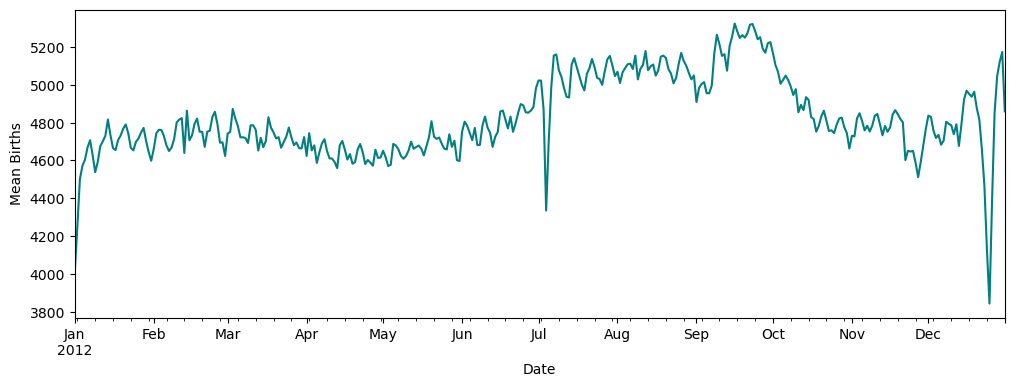

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Group cleaned data by month and day using a pivot table
births_by_date = births_cleaned.pivot_table(index=['month', 'day'], values='births', aggfunc='mean')

# (a) Convert (month, day) multi-index into dates using a dummy leap year (2012)
date_index = [pd.to_datetime(f'2012-{m}-{d}', errors='coerce') for m, d in births_by_date.index]
births_by_date.index = pd.DatetimeIndex(date_index)

# Display first few dates to inspect
print("--- Sample Parsed Dates and Mean Births ---")
print(births_by_date.head())

# (b) Plot mean births by date (figure size 12 x 4)
fig, ax = plt.subplots(figsize=(12, 4))
births_by_date.plot(ax=ax, color='teal', linewidth=1.5, legend=False)
plt.xlabel("Date")
plt.ylabel("Mean Births")
plt.show()

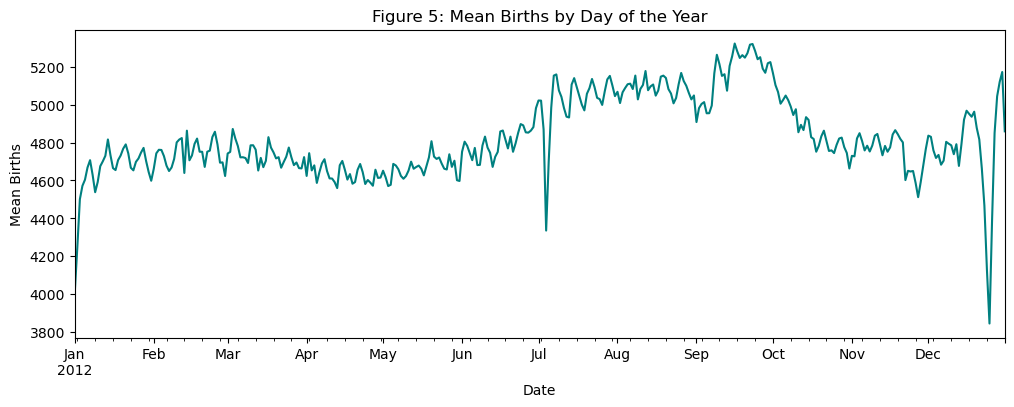

--- 5 Dates with Lowest Mean Births (Holiday Dips) ---
              births
2012-12-25  3844.450
2012-01-01  4009.225
2012-12-24  4126.250
2012-01-02  4247.400
2012-07-04  4335.325


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Group cleaned data by month and day with a pivot table
births_by_date = births_cleaned.pivot_table(index=['month', 'day'], values='births', aggfunc='mean')

# (a) Convert (month, day) multi-index into dates using a dummy leap year (2012)
date_index = [pd.to_datetime(f'2012-{m}-{d}', errors='coerce') for m, d in births_by_date.index]
births_by_date.index = pd.DatetimeIndex(date_index)

# (b) Plot mean births by date (figure size 12 x 4) with labeled axes
fig, ax = plt.subplots(figsize=(12, 4))
births_by_date.plot(ax=ax, color='teal', linewidth=1.5, legend=False)
plt.title("Figure 5: Mean Births by Day of the Year")
plt.xlabel("Date")
plt.ylabel("Mean Births")
plt.show()

# (c) Identify dates with the lowest mean births (holiday dips)
lowest_5 = births_by_date.sort_values(by='births').head(5)
print("--- 5 Dates with Lowest Mean Births (Holiday Dips) ---")
print(lowest_5)

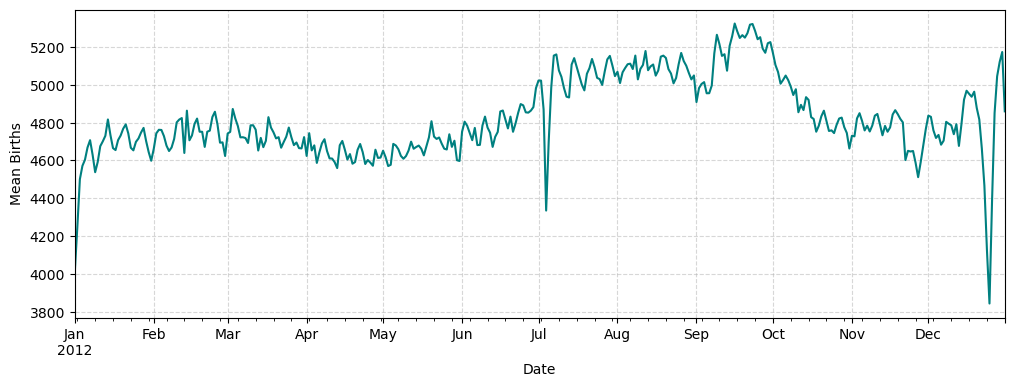

--- Top 5 Dates with Lowest Mean Births (Holiday Dips) ---
              births
2012-12-25  3844.450
2012-01-01  4009.225
2012-12-24  4126.250
2012-01-02  4247.400
2012-07-04  4335.325


In [15]:

import pandas as pd
import matplotlib.pyplot as plt

# Group the cleaned data by month and day to get the mean births for each calendar date
births_by_date = births_cleaned.pivot_table(index=['month', 'day'], values='births', aggfunc='mean')

# (a) Convert the (month, day) multi-index into dates using a dummy leap year (2012)
# Note: A leap year must be chosen so that February 29th (2012-02-29) parses correctly without errors.
date_index = [pd.to_datetime(f'2012-{m}-{d}', errors='coerce') for m, d in births_by_date.index]
births_by_date.index = pd.DatetimeIndex(date_index)

# (b) Plot the mean births by date (figure size 12 x 4) with labeled axes
fig, ax = plt.subplots(figsize=(12, 4))
births_by_date.plot(ax=ax, color='teal', linewidth=1.5, legend=False)
plt.xlabel("Date")
plt.ylabel("Mean Births")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# (c) Identify the calendar dates with the lowest mean births corresponding to US holidays
lowest_birth_dates = births_by_date.sort_values(by='births').head(5)
print("--- Top 5 Dates with Lowest Mean Births (Holiday Dips) ---")
print(lowest_birth_dates)


In [14]:
import pandas as pd
import timeit

# (a) Reproduce the decade-by-gender table using groupby and unstack
groupby_decade = births.groupby(['decade', 'gender'])['births'].sum().unstack()
print("--- Groupby & Unstack Result ---")
print(groupby_decade)

# Confirm it matches the pivot table from Task 2
match = pivot_decade.equals(groupby_decade)
print(f"\nDoes it match the pivot table? {match}")

# (b) Time both approaches and tabulate the results
t_pivot = timeit.timeit(
    "births.pivot_table(index='decade', columns='gender', values='births', aggfunc='sum')", 
    globals=globals(), 
    number=1000
)
t_groupby = timeit.timeit(
    "births.groupby(['decade', 'gender'])['births'].sum().unstack()", 
    globals=globals(), 
    number=1000
)

timing_df = pd.DataFrame({
    'Method': ['pivot_table', 'groupby + unstack'],
    'Execution Time (s for 1000 loops)': [t_pivot, t_groupby]
})
print("\n--- Performance Timing Results ---")
print(timing_df.to_string(index=False))

--- Groupby & Unstack Result ---
gender         F         M
decade                    
1960     1753634   1846572
1970    16263075  17121550
1980    18310351  19243452
1990    19479454  20420553
2000    18229309  19106428

Does it match the pivot table? False

--- Performance Timing Results ---
           Method  Execution Time (s for 1000 loops)
      pivot_table                          15.028753
groupby + unstack                           7.167137


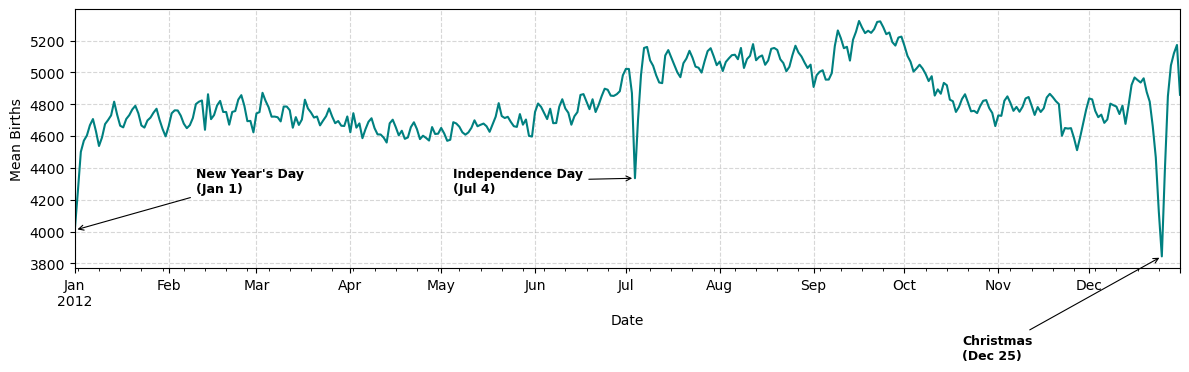

--- Top 5 Dates with Lowest Mean Births & Matched US Holidays ---
              births
2012-12-25  3844.450
2012-01-01  4009.225
2012-12-24  4126.250
2012-01-02  4247.400
2012-07-04  4335.325


In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Initialize figure for annotated plot
fig, ax = plt.subplots(figsize=(12, 4))
births_by_date.plot(ax=ax, color='teal', linewidth=1.5, legend=False)
plt.xlabel("Date")
plt.ylabel("Mean Births")
plt.grid(True, linestyle='--', alpha=0.5)

# Annotate at least three major holiday dips
# 1. Christmas Day (Dec 25)
ax.annotate('Christmas\n(Dec 25)', 
            xy=(pd.to_datetime('2012-12-25'), births_by_date.loc['2012-12-25', 'births']),
            xytext=(pd.to_datetime('2012-10-20'), 3200),
            arrowprops=dict(facecolor='black', arrowstyle='->', lw=0.8),
            fontsize=9, fontweight='semibold')

# 2. Independence Day (Jul 4)
ax.annotate('Independence Day\n(Jul 4)', 
            xy=(pd.to_datetime('2012-07-04'), births_by_date.loc['2012-07-04', 'births']),
            xytext=(pd.to_datetime('2012-05-05'), 4250),
            arrowprops=dict(facecolor='black', arrowstyle='->', lw=0.8),
            fontsize=9, fontweight='semibold')

# 3. New Year's Day (Jan 1)
ax.annotate("New Year's Day\n(Jan 1)", 
            xy=(pd.to_datetime('2012-01-01'), births_by_date.loc['2012-01-01', 'births']),
            xytext=(pd.to_datetime('2012-02-10'), 4250),
            arrowprops=dict(facecolor='black', arrowstyle='->', lw=0.8),
            fontsize=9, fontweight='semibold')

plt.tight_layout()
plt.show()

# Identify and display the top 5 lowest birth dates and their matched holidays
lowest_5 = births_by_date.sort_values(by='births').head(5)
print("--- Top 5 Dates with Lowest Mean Births & Matched US Holidays ---")
print(lowest_5)